# Tugas: Filtering Citra Berbasis Domain Frekuensi
Deskripsi Tugas
Cari beberapa jenis citra digital dengan karakteristik berbeda. Lakukan filtering menggunakan pendekatan domain frekuensi berbasis 2D FFT, kemudian lakukan analisis terhadap pengaruh setiap filter terhadap karakteristik citra.



## I. Frequency Domain Filtering
Implementasikan metode:

- Low-Pass Filter (LPF)
- High-Pass Filter (HPF)

Untuk setiap filter, variasikan nilai cutoff radius (D0) dan tunjukkan perbandingan hasil antar nilai D0.

## II. Dataset
Gunakan 3 citra digital, masing-masing mewakili satu karakteristik berikut:
- Citra 1 — Citra dengan tekstur halus
- Citra 2 — Citra dengan tepi/objek yang tajam
- Citra 3 — Citra dengan noise periodik

## III. Implementasi

Untuk setiap citra:
1. Input dan Preprocessing

- Load image
- Grayscale conversion

2. Visualisasi Spectrum

- Terapkan 2D FFT
- Tampilkan magnitude spectrum

3. Low-Pass Filter (LPF)

- Terapkan LPF dengan minimal 3 nilai D0 berbeda
- Tampilkan hasil rekonstruksi citra untuk setiap D0

4. High-Pass Filter (HPF)

- Terapkan HPF dengan minimal 3 nilai D0 berbeda
- Tampilkan hasil rekonstruksi citra untuk setiap D0

## IV. Analisis
Berikan analisis mengenai:
- Pada nilai D0 berapa detail citra mulai hilang (LPF) atau noise mulai muncul (HPF)?
- Rentang D0 yang paling optimal untuk masing-masing karakteristik citra
- Kesesuaian metode filter terhadap karakteristik citra

## Format Pengumpulan
Kumpulkan dalam satu folder ZIP dengan nama NRP_Nama_Filtering.zip, berisi:
- NRP_Nama_Filtering.ipynb (sudah dijalankan / semua output tersedia)
- File citra yang digunakan

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 110


def load_grayscale(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f'Citra tidak ditemukan atau tidak dapat dibaca: {path}')
    return image.astype(np.float32)


def distance_matrix(shape):
    rows, cols = shape
    y, x = np.ogrid[:rows, :cols]
    return np.sqrt((x - cols // 2) ** 2 + (y - rows // 2) ** 2)


def ideal_lpf(shape, d0):
    return (distance_matrix(shape) <= d0).astype(np.float32)


def ideal_hpf(shape, d0):
    return (distance_matrix(shape) > d0).astype(np.float32)


def frequency_filter(image, mask):
    spectrum = np.fft.fftshift(np.fft.fft2(image))
    filtered_spectrum = spectrum * mask
    result = np.real(np.fft.ifft2(np.fft.ifftshift(filtered_spectrum)))
    return np.clip(result, 0, 255)


def spectrum(image):
    shifted = np.fft.fftshift(np.fft.fft2(image))
    return np.log1p(np.abs(shifted))


def edge_energy(image):
    gx = cv2.Sobel(image, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(image, cv2.CV_32F, 0, 1, ksize=3)
    return float(np.mean(np.sqrt(gx * gx + gy * gy)))


In [2]:
IMAGE_DIR = Path('image')
image_files = {
    'Tekstur halus': IMAGE_DIR / 'smooth.jpeg',
    'Tepi/objek tajam': IMAGE_DIR / 'sharp.jpeg',
    'Noise periodik': IMAGE_DIR / 'pnois2.jpg',
}
D0_VALUES = (10, 30, 60)

images = {label: load_grayscale(path) for label, path in image_files.items()}

print('Dataset yang digunakan:')
for label, image in images.items():
    print(f'- {label}: {image_files[label].name}, ukuran {image.shape[1]} x {image.shape[0]} piksel')


Dataset yang digunakan:
- Tekstur halus: smooth.jpeg, ukuran 415 x 739 piksel
- Tepi/objek tajam: sharp.jpeg, ukuran 480 x 640 piksel
- Noise periodik: pnois2.jpg, ukuran 512 x 512 piksel


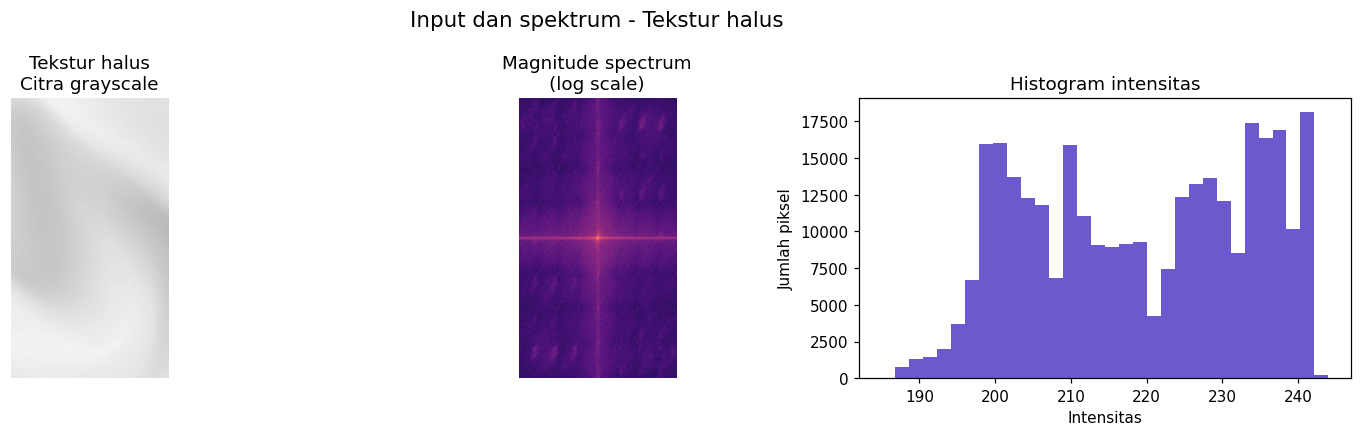

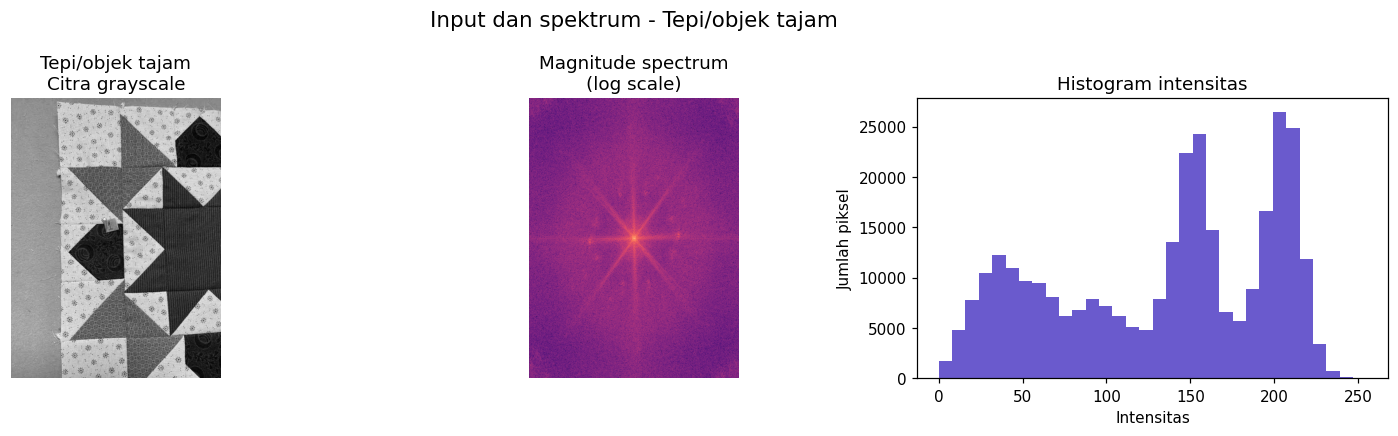

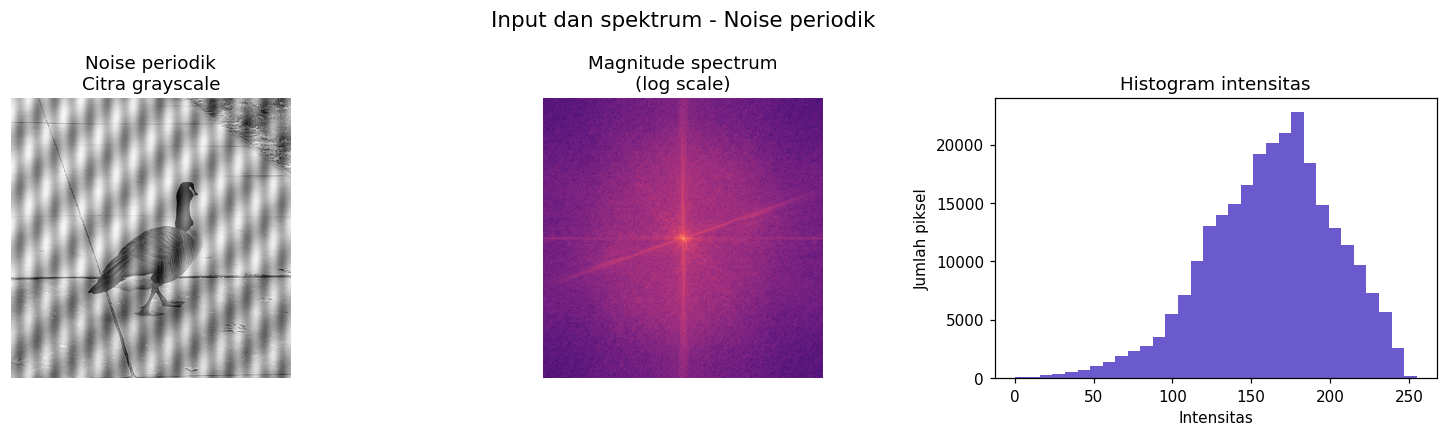

In [3]:
for label, image in images.items():
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title(f'{label}\nCitra grayscale')
    axes[1].imshow(spectrum(image), cmap='magma')
    axes[1].set_title('Magnitude spectrum\n(log scale)')
    axes[2].hist(image.ravel(), bins=32, color='slateblue')
    axes[2].set_title('Histogram intensitas')
    axes[2].set_xlabel('Intensitas')
    axes[2].set_ylabel('Jumlah piksel')
    for axis in axes[:2]:
        axis.axis('off')
    fig.suptitle(f'Input dan spektrum - {label}', fontsize=14)
    plt.tight_layout()
    plt.show()


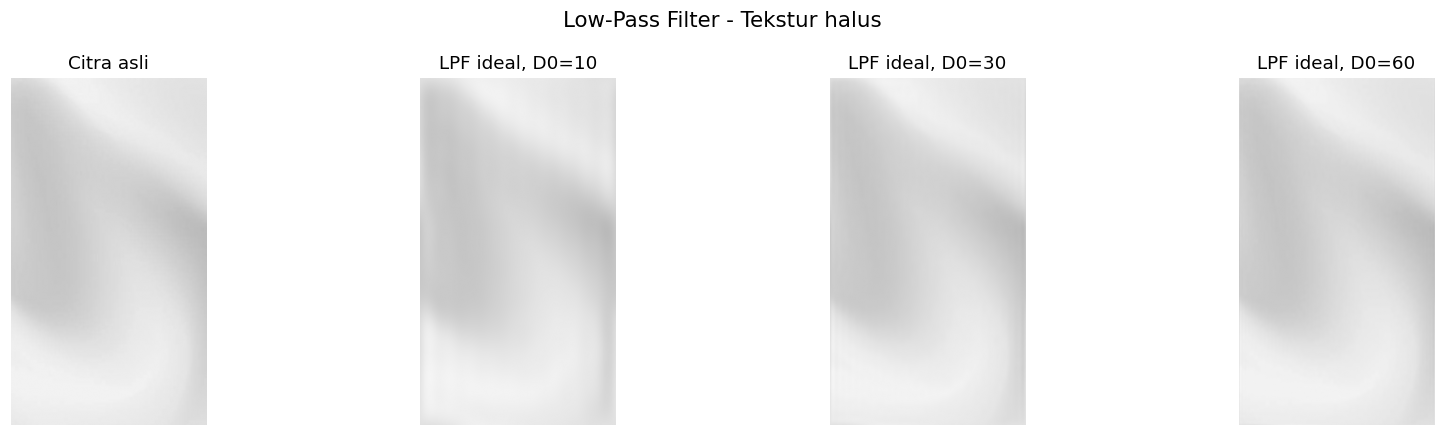

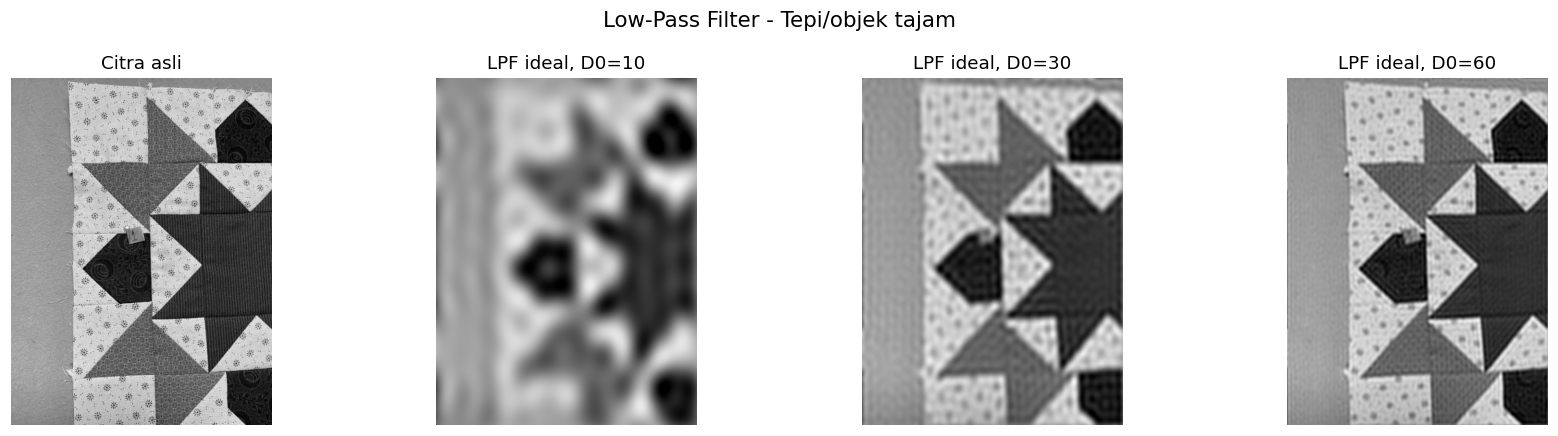

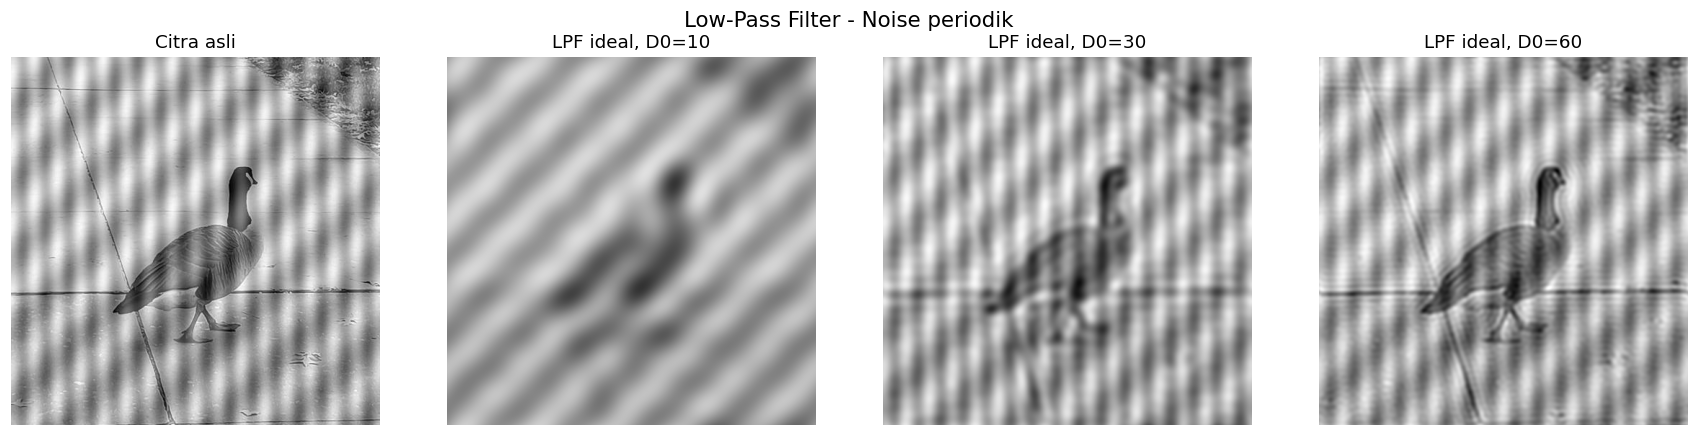

In [4]:
results = {}
for label, image in images.items():
    lpf_results = {d0: frequency_filter(image, ideal_lpf(image.shape, d0)) for d0 in D0_VALUES}
    results[label] = {'lpf': lpf_results}

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title('Citra asli')
    for column, d0 in enumerate(D0_VALUES, start=1):
        axes[column].imshow(lpf_results[d0], cmap='gray', vmin=0, vmax=255)
        axes[column].set_title(f'LPF ideal, D0={d0}')
    for axis in axes:
        axis.axis('off')
    fig.suptitle(f'Low-Pass Filter - {label}', fontsize=14)
    plt.tight_layout()
    plt.show()


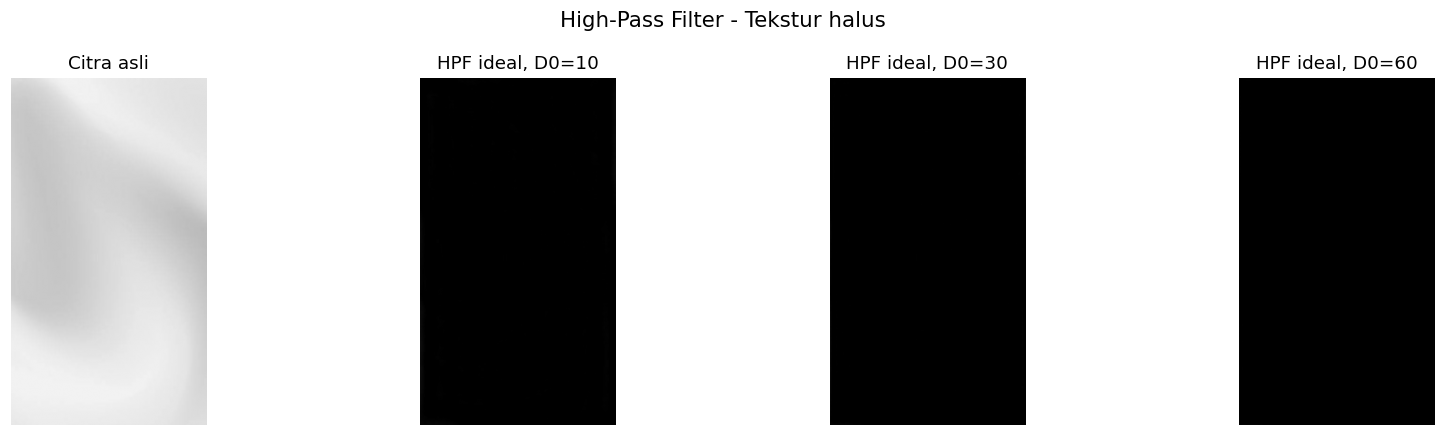

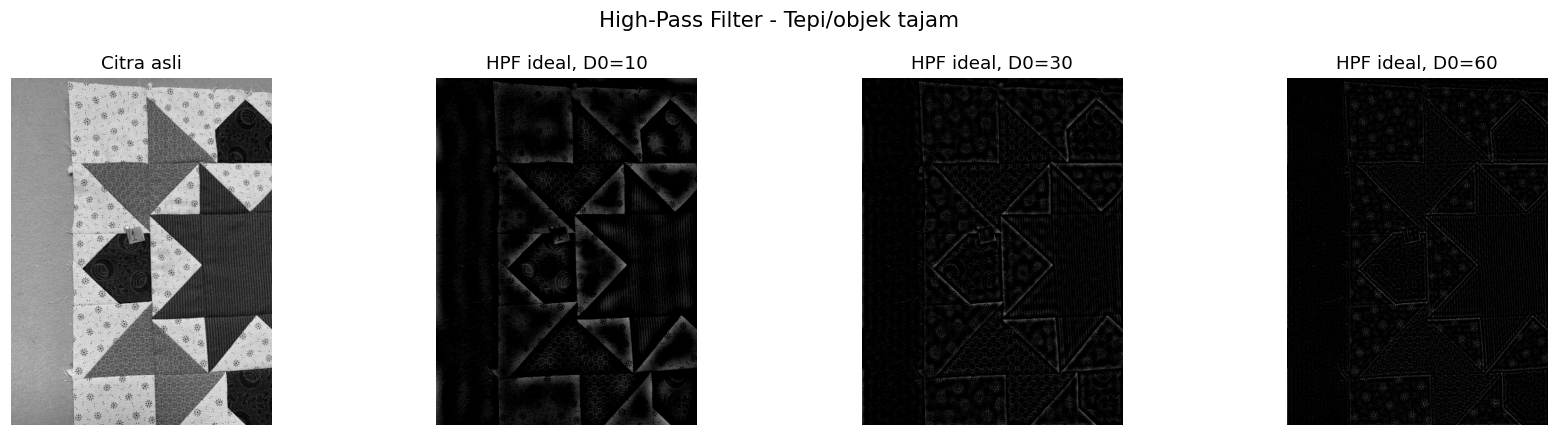

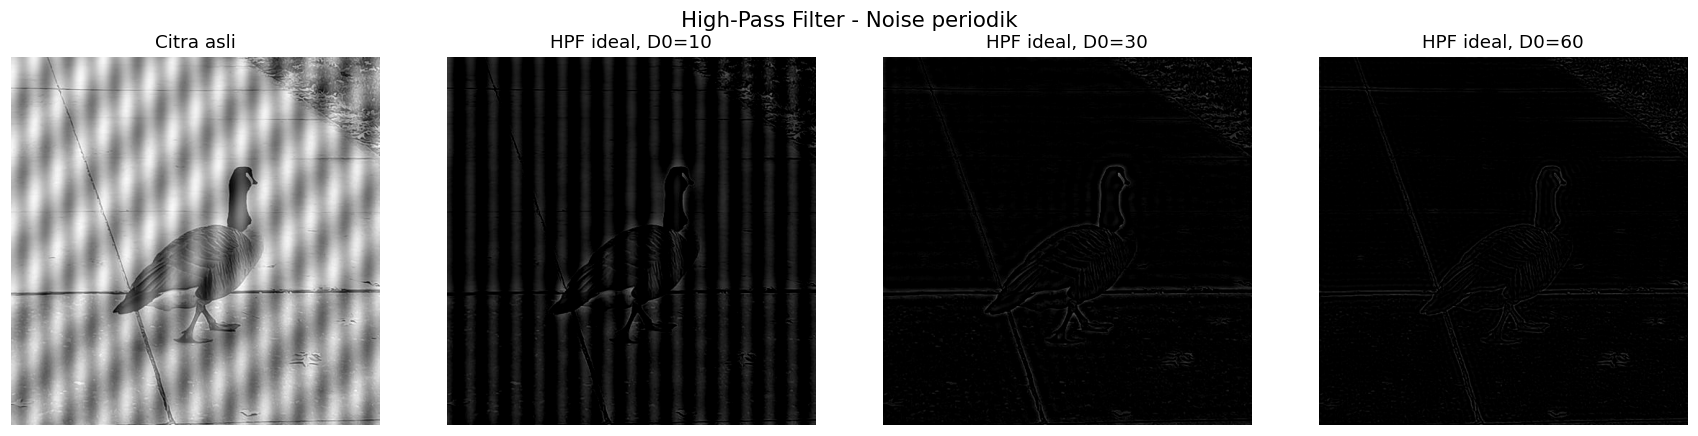

In [5]:
for label, image in images.items():
    hpf_results = {d0: frequency_filter(image, ideal_hpf(image.shape, d0)) for d0 in D0_VALUES}
    results[label]['hpf'] = hpf_results

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0].set_title('Citra asli')
    for column, d0 in enumerate(D0_VALUES, start=1):
        axes[column].imshow(hpf_results[d0], cmap='gray', vmin=0, vmax=255)
        axes[column].set_title(f'HPF ideal, D0={d0}')
    for axis in axes:
        axis.axis('off')
    fig.suptitle(f'High-Pass Filter - {label}', fontsize=14)
    plt.tight_layout()
    plt.show()


In [6]:
print('Metrik analisis (semakin besar edge energy berarti detail/tepi semakin kuat):')
for label, image in images.items():
    print(f'\n{label} | citra asli: std={np.std(image):.2f}, edge energy={edge_energy(image):.2f}')
    for d0 in D0_VALUES:
        lpf = results[label]['lpf'][d0]
        hpf = results[label]['hpf'][d0]
        print(f'  D0={d0:>2}: LPF std={np.std(lpf):>6.2f}, edge={edge_energy(lpf):>6.2f} | HPF std={np.std(hpf):>6.2f}, edge={edge_energy(hpf):>6.2f}')


Metrik analisis (semakin besar edge energy berarti detail/tepi semakin kuat):

Tekstur halus | citra asli: std=14.66, edge energy=2.34
  D0=10: LPF std= 14.56, edge=  1.93 | HPF std=  1.14, edge=  1.30
  D0=30: LPF std= 14.62, edge=  2.13 | HPF std=  0.68, edge=  1.34
  D0=60: LPF std= 14.64, edge=  2.47 | HPF std=  0.48, edge=  1.20

Tepi/objek tajam | citra asli: std=64.82, edge energy=86.04
  D0=10: LPF std= 56.15, edge= 16.97 | HPF std= 18.38, edge= 39.92
  D0=30: LPF std= 60.76, edge= 29.03 | HPF std= 12.54, edge= 42.36
  D0=60: LPF std= 62.09, edge= 38.56 | HPF std= 10.50, edge= 41.75

Noise periodik | citra asli: std=40.87, edge energy=55.81
  D0=10: LPF std= 31.23, edge= 15.61 | HPF std= 14.47, edge= 25.70
  D0=30: LPF std= 39.29, edge= 37.47 | HPF std=  6.85, edge= 18.58
  D0=60: LPF std= 39.79, edge= 42.03 | HPF std=  5.97, edge= 18.88


## IV. Analisis hasil

- **LPF:** semakin kecil `D0`, semakin sedikit frekuensi tinggi yang dilewatkan sehingga tekstur dan tepi makin halus/hilang. Pada percobaan ini, `D0=10` memberikan pengaburan paling kuat, sedangkan `D0=60` masih mempertahankan lebih banyak detail.
- **HPF:** semakin kecil `D0`, semakin banyak frekuensi tinggi yang dipertahankan dan hasil lebih menyerupai peta tepi. Pada citra `pnois2.jpg`, HPF juga menonjolkan noise periodik sehingga filter ini kurang sesuai untuk reduksi noise.
- **Rentang yang disarankan:** citra tekstur halus cocok menggunakan LPF `D0=30-60`; citra dengan tepi tajam lebih informatif dengan HPF `D0=10-30` untuk ekstraksi tepi atau LPF `D0=60` jika ingin mengurangi noise tanpa terlalu menghilangkan kontur; citra noise periodik sebaiknya tidak hanya memakai LPF/HPF ideal, tetapi dilanjutkan dengan notch filter pada frekuensi noise.
- **Kesimpulan:** LPF sesuai untuk penghalusan dan pengurangan komponen frekuensi tinggi, sedangkan HPF sesuai untuk menonjolkan tepi/detail. Nilai cutoff harus dipilih berdasarkan karakteristik citra dan tujuan pemrosesan.